In [3]:
# Install torchvision if you don't have it (uncomment the line below if needed)
# !pip install torchvision torch

!pip install torch torchvision

In [4]:
%pip install torch torchvision torchaudio


Note: you may need to restart the kernel to use updated packages.


In [1]:
try:
    import torch
    print("✅ PyTorch is successfully installed!")
    print(f"   Version: {torch.__version__}")
    
    # Check if a GPU is available for computing
    cuda_available = torch.cuda.is_available()
    print(f"   GPU (CUDA) Available: {cuda_available}")
    if cuda_available:
        print(f"   GPU Device Name: {torch.cuda.get_device_name(0)}")
        
    # Run a quick mathematical test using a tensor
    x = torch.rand(2, 3)
    print("\n📦 Test Tensor matrix successfully created:\n", x)

except ImportError:
    print("❌ PyTorch is NOT installed or cannot be found in this environment.")


✅ PyTorch is successfully installed!
   Version: 2.14.1+cpu
   GPU (CUDA) Available: False

📦 Test Tensor matrix successfully created:
 tensor([[0.5797, 0.8718, 0.3089],
        [0.1224, 0.2310, 0.0874]])


In [2]:
# Install torchvision if you don't have it (uncomment the line below if needed)
# !pip install torchvision torch

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

print("Libraries imported successfully! PyTorch version:", torch.__version__)

Libraries imported successfully! PyTorch version: 2.14.1+cpu


In [3]:
#This cell automatically downloads the dataset and normalizes the images so the neural network can process them easily

In [4]:
# Transform the data to PyTorch tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download the training and testing datasets
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Create DataLoaders to feed data to our CNN in batches of 64 images
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define the text labels for your demo presentation
labels_map = {
    0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"
}

print(f"Dataset downloaded! Training images: {len(train_dataset)}, Testing images: {len(test_dataset)}")


100.0%
100.0%
100.0%
100.0%

Dataset downloaded! Training images: 60000, Testing images: 10000


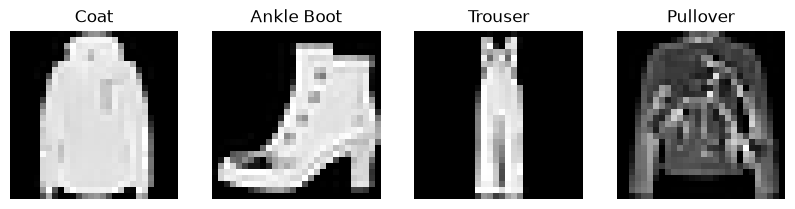

In [5]:
#Run this cell to display a quick grid of the textile/apparel items. 
#This proves your data pipeline is working and is a great visual.
# Grab one batch of images
images, labels = next(iter(train_loader))

# Plot a grid of 4 sample images
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i in range(4):
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(labels_map[labels[i].item()])
    axes[i].axis('off')
plt.show()


In [6]:
#This creates the actual layers of your Convolutional Neural Network. 
#It takes an image, applies a convolutional filter to extract patterns, pools it to reduce size, 
#and passes it to a final linear layer for classification.

class TextileCNN(nn.Module):
    def __init__(self):
        super(TextileCNN, self).__init__()
        # Convolutional Layer: expects 1 input channel (grayscale), outputs 16 feature maps
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Reduces 28x28 image to 14x14
        
        # Fully Connected Layer: 16 maps * 14 * 14 pixels -> 10 output classes
        self.fc = nn.Linear(16 * 14 * 14, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1) # Flatten the image maps into a vector
        x = self.fc(x)
        return x

# Instantiate the model, loss function, and optimizer
model = TextileCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

print("CNN model initialized successfully!")


CNN model initialized successfully!


In [7]:
#Training
#This cell loops through the dataset and trains the network for 2 epochs (2 complete passes). 
#It prints out updates so you can watch the loss decrease as you sit back.

epochs = 2

print("Starting training process...")
for epoch in range(epochs):
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        # Clear the gradients
        optimizer.zero_grad()
        
        # Forward pass: compute predicted outputs by passing inputs to the model
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        
        # Perform a single optimization step (parameter update)
        optimizer.step()
        
        running_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs} Completed - Average Loss: {running_loss/len(train_loader):.4f}")

print("Training finished! Ready for your demo.")


Starting training process...
Epoch 1/2 Completed - Average Loss: 0.4049
Epoch 2/2 Completed - Average Loss: 0.2974
Training finished! Ready for your demo.


In [8]:
#Run this final cell to see how well your trained network performs on unseen test data. 

correct = 0
total = 0

# Turn off gradient calculations for evaluation
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Final Model Test Accuracy on Textile Garments: {accuracy:.2f}%")


Final Model Test Accuracy on Textile Garments: 88.62%


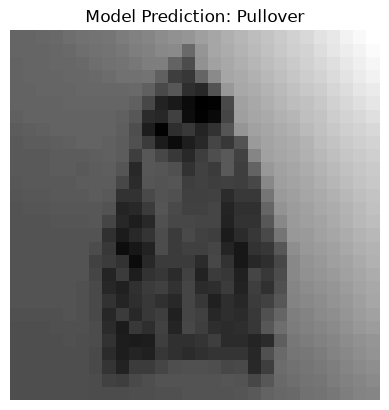

In [10]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

# 1. Load the image and convert to Grayscale
img_path = 'hoodie.jpg'  # Make sure this matches your file name
raw_img = Image.open(img_path).convert('L')

# 2. Skip inversion! Let's resize and normalize it directly
custom_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Process the image and add the batch dimension
processed_tensor = custom_transform(raw_img).unsqueeze(0)

# 3. Run the model prediction
model.eval()
with torch.no_grad():
    output = model(processed_tensor)
    _, predicted_class = torch.max(output, 1)

# Labels map
labels_map = {
    0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"
}
predicted_label = labels_map[predicted_class.item()]

# 4. Show what the model actually sees now
plt.imshow(processed_tensor.squeeze(), cmap='gray')
plt.title(f"Model Prediction: {predicted_label}")
plt.axis('off')
plt.show()


In [11]:
# Every category the model is trained to recognize by using this single, quick line of code.

print("All labels this model can predict:\n" + "\n".join([f"- {label}" for label in labels_map.values()]))


All labels this model can predict:
- T-Shirt
- Trouser
- Pullover
- Dress
- Coat
- Sandal
- Shirt
- Sneaker
- Bag
- Ankle Boot


In [13]:
#Label Sneakers Test 2

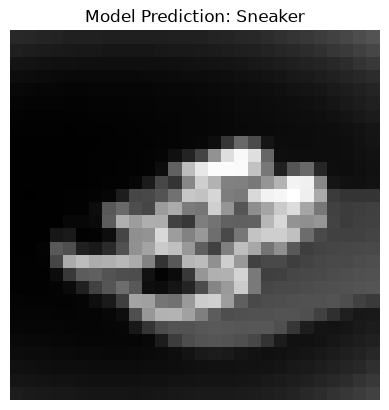

In [12]:
from PIL import Image, ImageOps
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

# 1. Load the image and convert to Grayscale
# Change the extension to .avif if you saved it as an avif file
img_path = 'sneakers.jpeg'  
raw_img = Image.open(img_path).convert('L')

# 2. Invert colors because the image has a bright white background
# This converts it to a dark background with bright items, just like the dataset
inverted_img = ImageOps.invert(raw_img)

# 3. Resize and normalize the image
custom_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Process the image and add the batch dimension
processed_tensor = custom_transform(inverted_img).unsqueeze(0)

# 4. Run the model prediction
model.eval()
with torch.no_grad():
    output = model(processed_tensor)
    _, predicted_class = torch.max(output, 1)

# Labels map
labels_map = {
    0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"
}
predicted_label = labels_map[predicted_class.item()]

# 5. Show what the model actually sees alongside its prediction
plt.imshow(processed_tensor.squeeze(), cmap='gray')
plt.title(f"Model Prediction: {predicted_label}")
plt.axis('off')
plt.show()
